## 0. Google Colab setup

In [ ]:
!pip install -q --upgrade "xgboost==3.4.1"


In [ ]:
# 1. Environment record
import sys, platform, os, json, hashlib, zipfile, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost as xgb

from sklearn.model_selection import GroupKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

print("Python       :", sys.version)
print("Platform     :", platform.platform())
print("NumPy        :", np.__version__)
print("Pandas       :", pd.__version__)
print("scikit-learn :", sklearn.__version__)
print("XGBoost      :", xgb.__version__)

assert tuple(map(int, xgb.__version__.split(".")[:2])) >= (3, 4), (
    "Restart the Colab runtime and rerun from the first cell so XGBoost 3.4.1 is actually loaded."
)


Python       : 3.13.15 (main, Aug  6 2026, 11:06:23) [GCC 11.4.0]
Platform     : Linux-6.6.122+-x86_64-with-glibc2.35
NumPy        : 2.1.3
Pandas       : 2.2.3
scikit-learn : 1.6.1
XGBoost      : 3.4.1


In [ ]:
# 2. Upload the corrected training dataset only
from google.colab import files
uploaded = files.upload()

csvs = [fn for fn in uploaded if fn.lower().endswith(".csv")]
if len(csvs) != 1:
    raise ValueError("Please upload only the corrected training file: Rdkit_10_修改.csv")

DATA_FILE = csvs[0]
print("Using:", DATA_FILE)


Saving Rdkit_10_修改.csv to Rdkit_10_修改 (1).csv
Using: Rdkit_10_修改 (1).csv


In [ ]:
# 3. Load and audit the corrected dataset

def sha256sum(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

df = pd.read_csv(DATA_FILE, encoding="unicode_escape")

assert "smile" in df.columns, "Expected a 'smile' column."
assert "PCE" in df.columns, "Expected a 'PCE' target column."

all_predictors = [c for c in df.columns if c not in ("smile", "PCE")]

# In the corrected dataset, the first 196 predictors are RDKit descriptors,
# followed by 24 device-processing/composition variables.
rdkit_cols = all_predictors[:196]
device_cols = all_predictors[196:]

y = df["PCE"].astype(float).copy()
groups = df["smile"].astype(str).copy()

print("Dataset shape:", df.shape)
print("All predictors:", len(all_predictors))
print("RDKit descriptors:", len(rdkit_cols))
print("Device variables:", len(device_cols))
print("Unique exact SMILES:", groups.nunique())
print("Repeated molecular identities:", int((groups.value_counts() > 1).sum()))
print("Maximum records / molecule:", int(groups.value_counts().max()))
print("SHA256:", sha256sum(DATA_FILE))

print("\nRDKit boundary:")
print("  First RDKit :", rdkit_cols[0])
print("  Last RDKit  :", rdkit_cols[-1])

print("\nDevice variables:")
print(device_cols)

assert df.shape == (99, 222), "Expected 99 rows and 222 total columns."
assert len(all_predictors) == 220, "Expected 220 corrected predictors."
assert len(rdkit_cols) == 196, "Expected 196 RDKit descriptors."
assert len(device_cols) == 24, "Expected 24 device variables."
assert rdkit_cols[-1] == "fr_urea", "Unexpected RDKit/device boundary."
assert device_cols[0] == "NiO2", "Unexpected first device variable."
assert groups.nunique() == 57, "Expected 57 unique exact-SMILES molecular identities."
assert df[all_predictors].isna().sum().sum() == 0, "Missing predictor values detected."


Dataset shape: (99, 222)
All predictors: 220
RDKit descriptors: 196
Device variables: 24
Unique exact SMILES: 57
Repeated molecular identities: 15
Maximum records / molecule: 7
SHA256: 8fc3f1345859bd7539907561bc7729fffd9e977dfff6fa7a605744a3dd32bbe2

RDKit boundary:
  First RDKit : BalabanJ
  Last RDKit  : fr_urea

Device variables:
['NiO2', 'ethanol', 'toluene', 'isopropanol', 'tetrahydrofuran', 'chlorobenzene', '2-Methoxyethanol', 'CH2CL2', 'Concentration(mg/mL)', 'wash', 'E', 'Cs', 'FA', 'MA', 'Pb', 'Sn', 'I', 'Br', 'CL', 'C60', 'BCP', 'PCBM', 'PEAI', 'ALD-SnO2']


## 4. Define the three main feature representations



In [ ]:
FEATURE_SETS = {
    "RDKit + Device": all_predictors,
    "Device only": device_cols,
    "RDKit only": rdkit_cols,
}

for name, cols in FEATURE_SETS.items():
    print(f"{name:16s}: {len(cols)} predictors")


RDKit + Device  : 220 predictors
Device only     : 24 predictors
RDKit only      : 196 predictors


## 5. Run settings


In [ ]:
RUN_MODE = "publication"

if RUN_MODE == "publication":
    N_REPEATS = 20
    OUTER_FOLDS = 5
    INNER_FOLDS = 4
    N_ITER = 16
elif RUN_MODE == "quick":
    N_REPEATS = 2
    OUTER_FOLDS = 5
    INNER_FOLDS = 3
    N_ITER = 6
else:
    raise ValueError("RUN_MODE must be 'publication' or 'quick'.")

# Use the same repetition seeds as Figure 1 to keep the analysis paired and auditable.
REPEAT_SEEDS = list(range(2101, 2101 + N_REPEATS))
MODEL_SEED = 2026
SEARCH_SEED = 2026

print("Mode:", RUN_MODE)
print("Repeats:", N_REPEATS)
print("Outer folds:", OUTER_FOLDS)
print("Inner folds:", INNER_FOLDS)
print("Candidates / outer fold:", N_ITER)


Mode: publication
Repeats: 20
Outer folds: 5
Inner folds: 4
Candidates / outer fold: 16


## 6. Common XGBoost model and search space



In [ ]:
PARAM_DISTRIBUTIONS = {
    "model__n_estimators": [150, 300, 430, 600],
    "model__learning_rate": [0.03, 0.10, 0.30, 0.60, 0.90],
    "model__max_depth": [2, 3, 4, 6],
    "model__min_child_weight": [1, 3, 5, 8],
    "model__subsample": [0.70, 0.90, 1.00],
    "model__colsample_bytree": [0.05, 0.20, 0.50, 0.80, 1.00],
    "model__gamma": [0.00, 0.10, 0.50],
    "model__reg_alpha": [0.00, 0.10, 1.00],
    "model__reg_lambda": [1.00, 5.00, 10.00],
}

def make_pipeline():
    # Scaling is retained for consistency with the released workflow.
    # Keeping it inside Pipeline guarantees training-fold-only fitting.
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", xgb.XGBRegressor(
            objective="reg:squarederror",
            random_state=MODEL_SEED,
            n_jobs=1,
            tree_method="hist",
            verbosity=0,
        ))
    ])

def make_search(inner_cv):
    return RandomizedSearchCV(
        estimator=make_pipeline(),
        param_distributions=PARAM_DISTRIBUTIONS,
        n_iter=N_ITER,
        scoring="neg_root_mean_squared_error",
        cv=inner_cv,
        refit=True,
        random_state=SEARCH_SEED,
        n_jobs=-1,
        error_score="raise",
        return_train_score=False,
    )

def calc_metrics(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
    }


## 7. Repeated nested molecule-wise OOF feature-ablation benchmark


In [ ]:
def run_one_repetition(repeat_seed):
    n = len(df)

    # Precompute ONE set of outer group folds and reuse it for all feature sets.
    outer_cv = GroupKFold(
        n_splits=OUTER_FOLDS,
        shuffle=True,
        random_state=repeat_seed,
    )
    outer_splits = list(outer_cv.split(df, y, groups=groups))

    repeat_rows = []
    fold_rows = []
    pred_rows = []

    for feature_name, cols in FEATURE_SETS.items():
        X_feature = df[cols].copy()
        oof_pred = np.full(n, np.nan, dtype=float)

        for fold, (tr_idx, te_idx) in enumerate(outer_splits, start=1):
            # Hard outer-leakage check
            train_groups = set(groups.iloc[tr_idx])
            test_groups = set(groups.iloc[te_idx])
            overlap = train_groups & test_groups
            assert len(overlap) == 0, f"Outer molecular-identity leakage detected: {overlap}"

            inner_cv = GroupKFold(
                n_splits=INNER_FOLDS,
                shuffle=True,
                random_state=repeat_seed * 100 + fold,
            )

            search = make_search(inner_cv)
            search.fit(
                X_feature.iloc[tr_idx],
                y.iloc[tr_idx],
                groups=groups.iloc[tr_idx],
            )

            pred = search.predict(X_feature.iloc[te_idx])
            oof_pred[te_idx] = pred

            fold_rows.append({
                "repeat_seed": repeat_seed,
                "feature_set": feature_name,
                "fold": fold,
                "n_features": len(cols),
                "n_train": len(tr_idx),
                "n_test": len(te_idx),
                "n_train_molecules": groups.iloc[tr_idx].nunique(),
                "n_test_molecules": groups.iloc[te_idx].nunique(),
                "molecular_identity_overlap": 0,
                "inner_best_RMSE": -search.best_score_,
                "best_params": json.dumps(search.best_params_, sort_keys=True),
            })

        assert not np.isnan(oof_pred).any(), (
            f"Missing OOF predictions for {feature_name}, seed {repeat_seed}"
        )

        m = calc_metrics(y, oof_pred)

        repeat_rows.append({
            "repeat_seed": repeat_seed,
            "feature_set": feature_name,
            "n_features": len(cols),
            **m,
        })

        pred_rows.append(pd.DataFrame({
            "row_index": np.arange(n),
            "smile": groups.values,
            "PCE_true": y.values,
            "PCE_pred": oof_pred,
            "repeat_seed": repeat_seed,
            "feature_set": feature_name,
        }))

    return (
        pd.DataFrame(repeat_rows),
        pd.DataFrame(fold_rows),
        pd.concat(pred_rows, ignore_index=True),
    )


all_repeat = []
all_fold = []
all_pred = []

t0 = time.time()

for i, seed in enumerate(REPEAT_SEEDS, start=1):
    r, f, p = run_one_repetition(seed)

    all_repeat.append(r)
    all_fold.append(f)
    all_pred.append(p)

    vals = r.set_index("feature_set")["R2"]
    print(
        f"[{i:02d}/{N_REPEATS}] OOF R² | "
        f"Full={vals['RDKit + Device']:+.3f}, "
        f"Device={vals['Device only']:+.3f}, "
        f"RDKit={vals['RDKit only']:+.3f}"
    )

repeat_results = pd.concat(all_repeat, ignore_index=True)
fold_audit = pd.concat(all_fold, ignore_index=True)
oof_predictions = pd.concat(all_pred, ignore_index=True)

print(f"\nFinished in {(time.time()-t0)/60:.1f} min")
display(repeat_results.head(9))


[01/20] OOF R² | Full=+0.388, Device=+0.172, RDKit=+0.304
[02/20] OOF R² | Full=+0.329, Device=+0.246, RDKit=+0.093
[03/20] OOF R² | Full=+0.444, Device=+0.352, RDKit=+0.316
[04/20] OOF R² | Full=+0.278, Device=+0.215, RDKit=+0.208
[05/20] OOF R² | Full=+0.201, Device=+0.324, RDKit=+0.338
[06/20] OOF R² | Full=+0.384, Device=+0.073, RDKit=+0.369
[07/20] OOF R² | Full=+0.396, Device=+0.226, RDKit=+0.217
[08/20] OOF R² | Full=+0.217, Device=+0.211, RDKit=+0.307
[09/20] OOF R² | Full=+0.205, Device=+0.146, RDKit=+0.228
[10/20] OOF R² | Full=+0.250, Device=+0.081, RDKit=+0.173
[11/20] OOF R² | Full=+0.459, Device=+0.274, RDKit=+0.234
[12/20] OOF R² | Full=+0.390, Device=+0.360, RDKit=+0.289
[13/20] OOF R² | Full=+0.415, Device=+0.284, RDKit=+0.160
[14/20] OOF R² | Full=+0.206, Device=+0.260, RDKit=+0.089
[15/20] OOF R² | Full=+0.323, Device=+0.315, RDKit=+0.223
[16/20] OOF R² | Full=+0.347, Device=+0.215, RDKit=+0.085
[17/20] OOF R² | Full=+0.189, Device=+0.355, RDKit=+0.241
[18/20] OOF R²

,repeat_seed,feature_set,n_features,R2,RMSE,MAE
0,2101,RDKit + Device,220,0.388368,2.554738,1.782263
1,2101,Device only,24,0.171698,2.973005,2.250510
2,2101,RDKit only,196,0.303594,2.726043,2.024329
3,2102,RDKit + Device,220,0.329396,2.675066,1.988811
4,2102,Device only,24,0.245957,2.836608,2.124174
5,2102,RDKit only,196,0.093238,3.110627,2.350154
6,2103,RDKit + Device,220,0.443897,2.436008,1.804088
7,2103,Device only,24,0.351725,2.630153,1.864494
8,2103,RDKit only,196,0.315602,2.702437,1.994686


## 8. Main summary



In [ ]:
ORDER = ["RDKit + Device", "Device only", "RDKit only"]

summary = (
    repeat_results.groupby("feature_set")[["R2", "RMSE", "MAE"]]
    .agg(["mean", "std", "median", "min", "max"])
    .reindex(ORDER)
)

display(summary.round(4))

wide_r2 = repeat_results.pivot(
    index="repeat_seed",
    columns="feature_set",
    values="R2",
)

delta_full_minus_device = wide_r2["RDKit + Device"] - wide_r2["Device only"]
delta_full_minus_rdkit = wide_r2["RDKit + Device"] - wide_r2["RDKit only"]
delta_device_minus_rdkit = wide_r2["Device only"] - wide_r2["RDKit only"]

paired_deltas = pd.DataFrame({
    "repeat_seed": wide_r2.index,
    "Full_minus_Device_R2": delta_full_minus_device.values,
    "Full_minus_RDKit_R2": delta_full_minus_rdkit.values,
    "Device_minus_RDKit_R2": delta_device_minus_rdkit.values,
})

def describe_delta(name, values):
    values = np.asarray(values, dtype=float)
    print(f"\n{name}")
    print("  Mean   :", values.mean())
    print("  SD     :", values.std(ddof=1))
    print("  Median :", np.median(values))
    print("  Range  :", (values.min(), values.max()))
    print("  Positive in:", int(np.sum(values > 0)), "/", len(values), "repetitions")

describe_delta("Full − Device only (incremental RDKit value)", delta_full_minus_device)
describe_delta("Full − RDKit only (incremental device value)", delta_full_minus_rdkit)
describe_delta("Device only − RDKit only", delta_device_minus_rdkit)


R2                                    RMSE          \
                  mean     std  median     min     max    mean     std   
feature_set                                                              
RDKit + Device  0.3161  0.0879  0.3264  0.1890  0.4588  2.6962  0.1742   
Device only     0.2390  0.0823  0.2361  0.0727  0.3601  2.8458  0.1532   
RDKit only      0.2136  0.0903  0.2199  0.0509  0.3695  2.8923  0.1664   

                                           MAE                                  
                median     min     max    mean     std  median     min     max  
feature_set                                                                     
RDKit + Device  2.6811  2.4031  2.9417  1.9688  0.1391  1.9311  1.7823  2.2111  
Device only     2.8550  2.6131  3.1456  2.1122  0.1298  2.1331  1.8645  2.3365  
RDKit only      2.8851  2.5939  3.1825  2.1635  0.1423  2.1509  1.9284  2.4277


Full − Device only (incremental RDKit value)
  Mean   : 0.0771084783740262
  SD     : 0.11251913748317541
  Median : 0.08406548374714162
  Range  : (np.float64(-0.1656465027152736), np.float64(0.3112901893489286))
  Positive in: 17 / 20 repetitions

Full − RDKit only (incremental device value)
  Mean   : 0.10247860626020992
  SD     : 0.11645889603097449
  Median : 0.10122426933058287
  Range  : (np.float64(-0.1372240250403507), np.float64(0.2624410955350941))
  Positive in: 16 / 20 repetitions

Device only − RDKit only
  Mean   : 0.025370127886183737
  SD     : 0.11730715347566019
  Median : 0.039217573625774826
  Range  : (np.float64(-0.2967048700349323), np.float64(0.17127559840435025))
  Positive in: 14 / 20 repetitions


## 9. Partition-resampling intervals for paired differences


In [ ]:
def bootstrap_mean_ci(values, n_boot=10000, seed=2026):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    boot = np.empty(n_boot)
    for i in range(n_boot):
        boot[i] = rng.choice(values, size=len(values), replace=True).mean()
    return np.percentile(boot, [2.5, 97.5])

delta_table = []

for i, (label, values) in enumerate([
    ("Full - Device only", delta_full_minus_device),
    ("Full - RDKit only", delta_full_minus_rdkit),
    ("Device only - RDKit only", delta_device_minus_rdkit),
]):
    ci = bootstrap_mean_ci(values, seed=2026 + i)
    delta_table.append({
        "Comparison": label,
        "Mean delta R2": np.mean(values),
        "SD delta R2": np.std(values, ddof=1),
        "Median delta R2": np.median(values),
        "95% interval low": ci[0],
        "95% interval high": ci[1],
        "Positive repetitions": int(np.sum(np.asarray(values) > 0)),
        "Total repetitions": len(values),
    })

delta_summary = pd.DataFrame(delta_table)
display(delta_summary.round(4))


,Comparison,Mean delta R2,SD delta R2,Median delta R2,95% interval low,95% interval high,Positive repetitions,Total repetitions
0,Full - Device only,0.0771,0.1125,0.0841,0.0286,0.1247,17,20
1,Full - RDKit only,0.1025,0.1165,0.1012,0.0523,0.1513,16,20
2,Device only - RDKit only,0.0254,0.1173,0.0392,-0.0275,0.0728,14,20


## 10. Figure 2



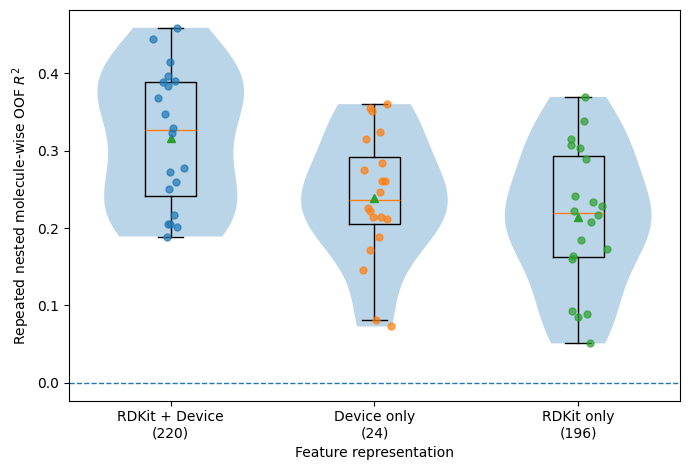

In [ ]:
plot_data = [
    repeat_results.loc[repeat_results.feature_set == name, "R2"].to_numpy()
    for name in ORDER
]

fig, ax = plt.subplots(figsize=(7.0, 4.8))
positions = [1, 2, 3]

ax.violinplot(
    plot_data,
    positions=positions,
    widths=0.72,
    showmeans=False,
    showmedians=False,
    showextrema=False,
)

ax.boxplot(
    plot_data,
    positions=positions,
    widths=0.25,
    showmeans=True,
    showfliers=False,
)

rng = np.random.default_rng(2026)
for xpos, vals in zip(positions, plot_data):
    jitter = rng.normal(0, 0.045, size=len(vals))
    ax.scatter(
        np.full(len(vals), xpos) + jitter,
        vals,
        s=25,
        alpha=0.70,
        zorder=3,
    )

ax.axhline(0, linestyle="--", linewidth=1.0)

ax.set_xticks(positions)
ax.set_xticklabels([
    "RDKit + Device\n(220)",
    "Device only\n(24)",
    "RDKit only\n(196)",
])
ax.set_ylabel(r"Repeated nested molecule-wise OOF $R^2$")
ax.set_xlabel("Feature representation")

fig.tight_layout()
fig.savefig("Figure2_feature_ablation_R2.svg", bbox_inches="tight")
fig.savefig("Figure2_feature_ablation_R2.pdf", bbox_inches="tight")
fig.savefig("Figure2_feature_ablation_R2.png", dpi=600, bbox_inches="tight")
plt.show()


## 11. Figure S2



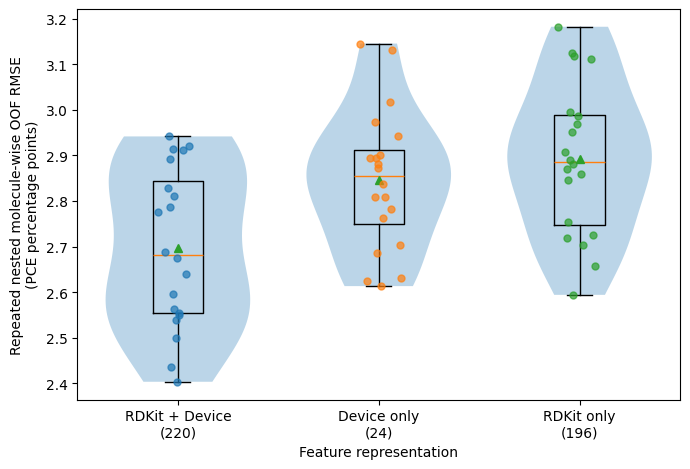

In [ ]:
plot_rmse = [
    repeat_results.loc[repeat_results.feature_set == name, "RMSE"].to_numpy()
    for name in ORDER
]

fig, ax = plt.subplots(figsize=(7.0, 4.8))
positions = [1, 2, 3]

ax.violinplot(
    plot_rmse,
    positions=positions,
    widths=0.72,
    showmeans=False,
    showmedians=False,
    showextrema=False,
)

ax.boxplot(
    plot_rmse,
    positions=positions,
    widths=0.25,
    showmeans=True,
    showfliers=False,
)

rng = np.random.default_rng(2027)
for xpos, vals in zip(positions, plot_rmse):
    jitter = rng.normal(0, 0.045, size=len(vals))
    ax.scatter(
        np.full(len(vals), xpos) + jitter,
        vals,
        s=25,
        alpha=0.70,
        zorder=3,
    )

ax.set_xticks(positions)
ax.set_xticklabels([
    "RDKit + Device\n(220)",
    "Device only\n(24)",
    "RDKit only\n(196)",
])
ax.set_ylabel("Repeated nested molecule-wise OOF RMSE\n(PCE percentage points)")
ax.set_xlabel("Feature representation")

fig.tight_layout()
fig.savefig("FigureS_feature_ablation_RMSE.svg", bbox_inches="tight")
fig.savefig("FigureS_feature_ablation_RMSE.pdf", bbox_inches="tight")
fig.savefig("FigureS_feature_ablation_RMSE.png", dpi=600, bbox_inches="tight")
plt.show()


## 12. Save the full audit trail



In [ ]:
repeat_results.to_csv("Figure2_repeat_level_metrics.csv", index=False)
fold_audit.to_csv("Figure2_outer_fold_audit.csv", index=False)
oof_predictions.to_csv("Figure2_all_OOF_predictions.csv", index=False)
paired_deltas.to_csv("Figure2_paired_delta_R2.csv", index=False)
delta_summary.to_csv("Figure2_paired_delta_summary.csv", index=False)

settings = {
    "data_file": DATA_FILE,
    "sha256": sha256sum(DATA_FILE),
    "shape": list(df.shape),
    "feature_sets": {k: len(v) for k, v in FEATURE_SETS.items()},
    "rdkit_first": rdkit_cols[0],
    "rdkit_last": rdkit_cols[-1],
    "device_first": device_cols[0],
    "device_last": device_cols[-1],
    "n_unique_smiles": int(groups.nunique()),
    "run_mode": RUN_MODE,
    "n_repeats": N_REPEATS,
    "outer_folds": OUTER_FOLDS,
    "inner_folds": INNER_FOLDS,
    "n_iter": N_ITER,
    "repeat_seeds": REPEAT_SEEDS,
    "model_seed": MODEL_SEED,
    "search_seed": SEARCH_SEED,
    "xgboost": xgb.__version__,
    "sklearn": sklearn.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "param_distributions": PARAM_DISTRIBUTIONS,
}

with open("Figure2_settings.json", "w", encoding="utf-8") as f:
    json.dump(settings, f, indent=2, ensure_ascii=False)

files_to_zip = [
    "Figure2_feature_ablation_R2.svg",
    "Figure2_feature_ablation_R2.pdf",
    "Figure2_feature_ablation_R2.png",
    "FigureS_feature_ablation_RMSE.svg",
    "FigureS_feature_ablation_RMSE.pdf",
    "FigureS_feature_ablation_RMSE.png",
    "Figure2_repeat_level_metrics.csv",
    "Figure2_outer_fold_audit.csv",
    "Figure2_all_OOF_predictions.csv",
    "Figure2_paired_delta_R2.csv",
    "Figure2_paired_delta_summary.csv",
    "Figure2_settings.json",
]

with zipfile.ZipFile("Figure2_feature_ablation_outputs.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for fn in files_to_zip:
        z.write(fn)

print("Created Figure2_feature_ablation_outputs.zip")


Created Figure2_feature_ablation_outputs.zip


In [ ]:
from google.colab import files
files.download("Figure2_feature_ablation_outputs.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Optional SI control — Device + permuted RDKit



In [ ]:
RUN_PERMUTED_CONTROL = True


In [ ]:
if RUN_PERMUTED_CONTROL:
    perm_repeat_rows = []
    perm_fold_rows = []

    for rep_i, repeat_seed in enumerate(REPEAT_SEEDS, start=1):
        outer_cv = GroupKFold(
            n_splits=OUTER_FOLDS,
            shuffle=True,
            random_state=repeat_seed,
        )
        outer_splits = list(outer_cv.split(df, y, groups=groups))

        oof_pred = np.full(len(df), np.nan, dtype=float)

        for fold, (tr_idx, te_idx) in enumerate(outer_splits, start=1):
            overlap = set(groups.iloc[tr_idx]) & set(groups.iloc[te_idx])
            assert len(overlap) == 0

            # Construct train/test separately.
            X_train_device = df.iloc[tr_idx][device_cols].reset_index(drop=True)
            X_test_device = df.iloc[te_idx][device_cols].reset_index(drop=True)

            X_train_rdkit = df.iloc[tr_idx][rdkit_cols].reset_index(drop=True)
            X_test_rdkit = df.iloc[te_idx][rdkit_cols].reset_index(drop=True)

            # Row-wise permutation destroys molecule-descriptor correspondence
            # while preserving the empirical descriptor vectors themselves.
            rng_train = np.random.default_rng(repeat_seed * 1000 + fold)
            rng_test = np.random.default_rng(repeat_seed * 1000 + fold + 500000)

            perm_train = rng_train.permutation(len(X_train_rdkit))
            perm_test = rng_test.permutation(len(X_test_rdkit))

            X_train_perm = pd.concat([
                X_train_rdkit.iloc[perm_train].reset_index(drop=True),
                X_train_device,
            ], axis=1)

            X_test_perm = pd.concat([
                X_test_rdkit.iloc[perm_test].reset_index(drop=True),
                X_test_device,
            ], axis=1)

            inner_cv = GroupKFold(
                n_splits=INNER_FOLDS,
                shuffle=True,
                random_state=repeat_seed * 100 + fold,
            )

            search = make_search(inner_cv)
            search.fit(
                X_train_perm,
                y.iloc[tr_idx].reset_index(drop=True),
                groups=groups.iloc[tr_idx].reset_index(drop=True),
            )

            pred = search.predict(X_test_perm)
            oof_pred[te_idx] = pred

            perm_fold_rows.append({
                "repeat_seed": repeat_seed,
                "fold": fold,
                "inner_best_RMSE": -search.best_score_,
                "best_params": json.dumps(search.best_params_, sort_keys=True),
            })

        assert not np.isnan(oof_pred).any()

        m = calc_metrics(y, oof_pred)
        perm_repeat_rows.append({
            "repeat_seed": repeat_seed,
            "feature_set": "Device + permuted RDKit",
            "n_features": 220,
            **m,
        })

        if rep_i == 1 or rep_i % 5 == 0 or rep_i == N_REPEATS:
            print(
                f"[{rep_i:02d}/{N_REPEATS}] "
                f"Device + permuted RDKit OOF R² = {m['R2']:+.3f}"
            )

    perm_results = pd.DataFrame(perm_repeat_rows)
    perm_folds = pd.DataFrame(perm_fold_rows)

    display(
        perm_results[["R2", "RMSE", "MAE"]]
        .agg(["mean", "std", "median", "min", "max"])
        .round(4)
    )

    # Paired comparison against real full model
    full_r2 = repeat_results[
        repeat_results.feature_set == "RDKit + Device"
    ].set_index("repeat_seed")["R2"]

    perm_r2 = perm_results.set_index("repeat_seed")["R2"]
    real_minus_perm = full_r2 - perm_r2

    print("\nReal Full − Device+Permuted RDKit ΔR²")
    print("Mean:", real_minus_perm.mean())
    print("SD:", real_minus_perm.std(ddof=1))
    print("Median:", real_minus_perm.median())
    print("Positive in:", int((real_minus_perm > 0).sum()), "/", len(real_minus_perm))

    perm_results.to_csv("FigureS_permuted_RDKit_repeat_metrics.csv", index=False)
    perm_folds.to_csv("FigureS_permuted_RDKit_fold_audit.csv", index=False)


[01/20] Device + permuted RDKit OOF R² = +0.276
[05/20] Device + permuted RDKit OOF R² = +0.246
[10/20] Device + permuted RDKit OOF R² = +0.177
[15/20] Device + permuted RDKit OOF R² = +0.167
[20/20] Device + permuted RDKit OOF R² = +0.175


,R2,RMSE,MAE
mean,0.1859,2.9437,2.2233
std,0.0865,0.1525,0.1476
median,0.1932,2.9340,2.2228
min,-0.0669,2.7394,2.0300
max,0.2968,3.3741,2.5503



Real Full − Device+Permuted RDKit ΔR²
Mean: 0.13020339566737366
SD: 0.10375474588077079
Median: 0.10806668940449737
Positive in: 18 / 20
